In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("Unemployment in India.csv")
df_regions = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

df.columns = df.columns.str.strip()
df_regions.columns = df_regions.columns.str.strip()

print("Main dataset shape:", df.shape)
print("Second dataset shape:", df_regions.shape)

display(df.head())
display(df_regions.head())

print("\nMissing values in main dataset:")
print(df.isna().sum())

Main dataset shape: (768, 7)
Second dataset shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74



Missing values in main dataset:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [2]:
# Work on a copy of the main dataset
df_clean = df.copy()

# Remove extra spaces from text columns
df_clean["Region"] = df_clean["Region"].str.strip()
df_clean["Area"] = df_clean["Area"].str.strip()

# Convert dates using day-month-year format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert numeric columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Check missing values before cleaning
print("Missing values before cleaning:")
display(df_clean.isna().sum())

# Remove rows missing essential analysis fields
df_clean = df_clean.dropna(
    subset=["Region", "Date", "Estimated Unemployment Rate (%)"]
)

print("\nDataset shape after cleaning:", df_clean.shape)
print("Remaining missing values:")
display(df_clean.isna().sum())

display(df_clean.head())

Missing values before cleaning:


Region                                      28
Date                                       768
Frequency                                   28
Estimated Unemployment Rate (%)             28
Estimated Employed                          28
Estimated Labour Participation Rate (%)     28
Area                                        28
dtype: int64


Dataset shape after cleaning: (0, 7)
Remaining missing values:


Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area


In [3]:
print("Dataset information:")
df_clean.info()

print("\nStatistical summary:")
display(df_clean.describe())

print("\nRegions:")
print(sorted(df_clean["Region"].unique()))

print("\nArea categories:")
print(df_clean["Area"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype        
---  ------                                   --------------  -----        
 0   Region                                   0 non-null      str          
 1   Date                                     0 non-null      datetime64[s]
 2   Frequency                                0 non-null      str          
 3   Estimated Unemployment Rate (%)          0 non-null      float64      
 4   Estimated Employed                       0 non-null      float64      
 5   Estimated Labour Participation Rate (%)  0 non-null      float64      
 6   Area                                     0 non-null      str          
dtypes: datetime64[s](1), float64(3), str(3)
memory usage: 132.0 bytes

Statistical summary:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,0,0.0,0.0,0.0
mean,NaT,NaN,NaN,NaN
min,NaT,NaN,NaN,NaN
25%,NaT,NaN,NaN,NaN
50%,NaT,NaN,NaN,NaN
75%,NaT,NaN,NaN,NaN
max,NaT,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN



Regions:
[]

Area categories:
Series([], Name: count, dtype: int64)


In [4]:
# Inspect the original dates before conversion
print("Original date values:")
display(df["Date"].head(10))

print("\nOriginal date data type:")
print(df["Date"].dtype)

print("\nDates after stripping spaces:")
display(df["Date"].astype(str).str.strip().head(10))


Original date values:


0     31-05-2019
1     30-06-2019
2     31-07-2019
3     31-08-2019
4     30-09-2019
5     31-10-2019
6     30-11-2019
7     31-12-2019
8     31-01-2020
9     29-02-2020
Name: Date, dtype: str


Original date data type:
str

Dates after stripping spaces:


0    31-05-2019
1    30-06-2019
2    31-07-2019
3    31-08-2019
4    30-09-2019
5    31-10-2019
6    30-11-2019
7    31-12-2019
8    31-01-2020
9    29-02-2020
Name: Date, dtype: str

In [5]:
df_clean = df.copy()

# Clean column names and text fields
df_clean.columns = df_clean.columns.str.strip()

df_clean["Region"] = df_clean["Region"].astype(str).str.strip()
df_clean["Area"] = df_clean["Area"].astype(str).str.strip()

# Handle dates robustly
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

# Convert numeric columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

print("Rows in original dataset:", len(df))
print("Valid dates:", df_clean["Date"].notna().sum())
print("Invalid dates:", df_clean["Date"].isna().sum())

# Remove rows missing essential fields
df_clean = df_clean.dropna(
    subset=["Region", "Date", "Estimated Unemployment Rate (%)"]
)

print("Rows after cleaning:", len(df_clean))
display(df_clean.head())


Rows in original dataset: 768
Valid dates: 740
Invalid dates: 28
Rows after cleaning: 740


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [6]:
print(df["Date"].head(10))


0     31-05-2019
1     30-06-2019
2     31-07-2019
3     31-08-2019
4     30-09-2019
5     31-10-2019
6     30-11-2019
7     31-12-2019
8     31-01-2020
9     29-02-2020
Name: Date, dtype: str


In [7]:
df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Valid dates:", df_clean["Date"].notna().sum())
print("Missing dates:", df_clean["Date"].isna().sum())

display(df_clean.head())

Valid dates: 0
Missing dates: 768


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,NaT,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,NaT,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,NaT,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,NaT,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,NaT,Monthly,5.17,12256762.0,44.68,Rural


In [8]:
print(repr(df["Date"].iloc[0]))
print(type(df["Date"].iloc[0]))
print(df["Date"].iloc[0] == "31-05-2019")

' 31-05-2019'
<class 'str'>
False


In [9]:
df_clean = df.copy()

# Remove extra spaces from dates
df_clean["Date"] = df_clean["Date"].str.strip()

# Convert dates into proper datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Valid dates:", df_clean["Date"].notna().sum())
print("Missing dates:", df_clean["Date"].isna().sum())

display(df_clean.head())

Valid dates: 740
Missing dates: 28


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [10]:
# Remove rows without valid dates
df_clean = df_clean.dropna(subset=["Date"]).copy()

# Clean text columns
df_clean["Region"] = df_clean["Region"].str.strip()
df_clean["Area"] = df_clean["Area"].str.strip()

# Convert numeric columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

print("Dataset shape:", df_clean.shape)
print("Missing values:")
display(df_clean.isna().sum())

display(df_clean.head())

Dataset shape: (740, 7)
Missing values:


Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [11]:
df_clean.info()

print("\nStatistical summary:")
display(df_clean.describe())

print("\nNumber of regions:", df_clean["Region"].nunique())
print("\nRural and urban records:")
print(df_clean["Area"].value_counts())

<class 'pandas.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    str           
 1   Date                                     740 non-null    datetime64[us]
 2   Frequency                                740 non-null    str           
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    str           
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 46.2 KB

Statistical summary:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094



Number of regions: 28

Rural and urban records:
Area
Urban    381
Rural    359
Name: count, dtype: int64


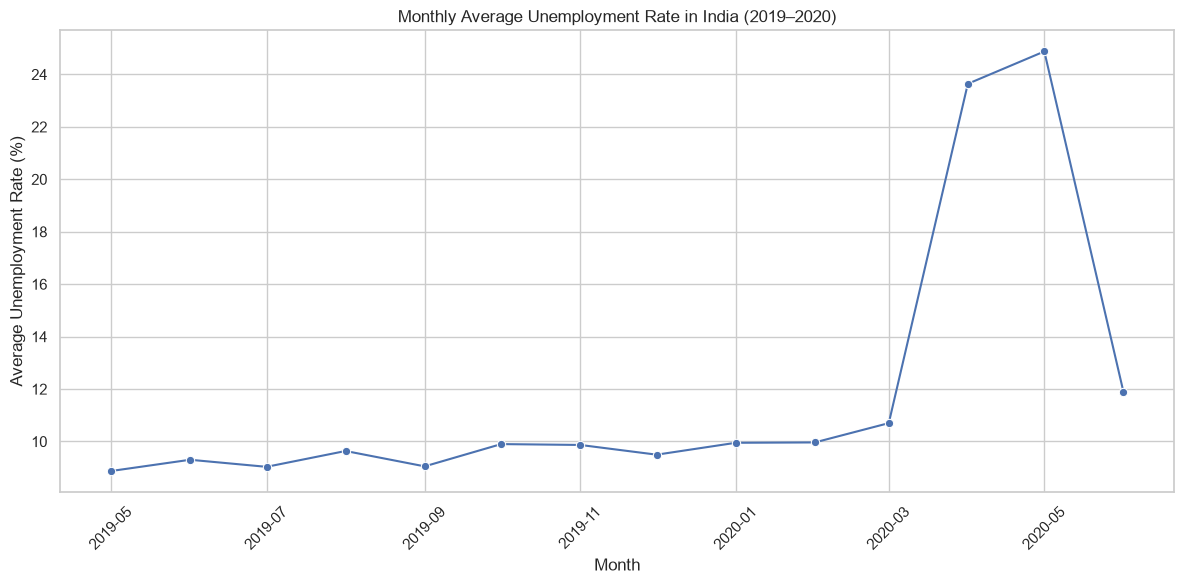

In [12]:
# Calculate average unemployment rate for each month
monthly_unemployment = (
    df_clean.groupby(df_clean["Date"].dt.to_period("M"))[
        "Estimated Unemployment Rate (%)"
    ]
    .mean()
    .reset_index()
)

monthly_unemployment["Date"] = (
    monthly_unemployment["Date"].dt.to_timestamp()
)

# Plot the trend
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_unemployment,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title("Monthly Average Unemployment Rate in India (2019–2020)")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

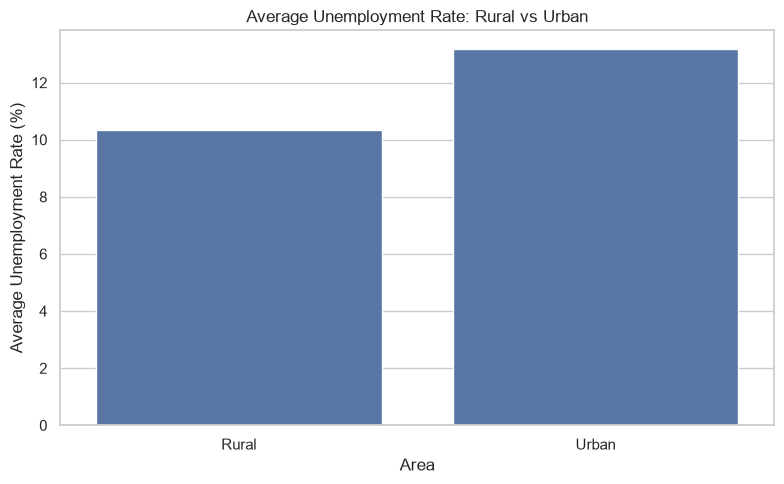

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Area",
    y="Estimated Unemployment Rate (%)",
    errorbar=None
)

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

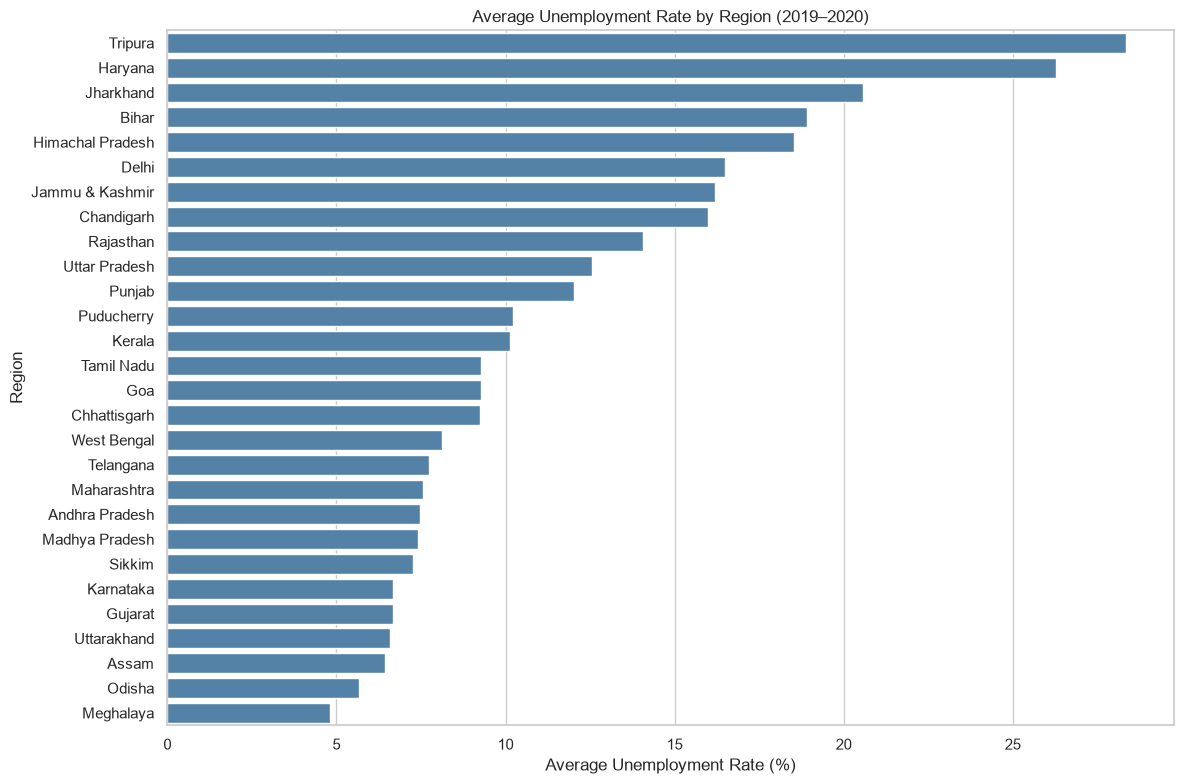

,Region,Estimated Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357


In [14]:
# Calculate average unemployment rate by region
region_unemployment = (
    df_clean.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=region_unemployment,
    x="Estimated Unemployment Rate (%)",
    y="Region",
    color="steelblue"
)

plt.title("Average Unemployment Rate by Region (2019–2020)")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Display the five highest averages
display(region_unemployment.head(5))

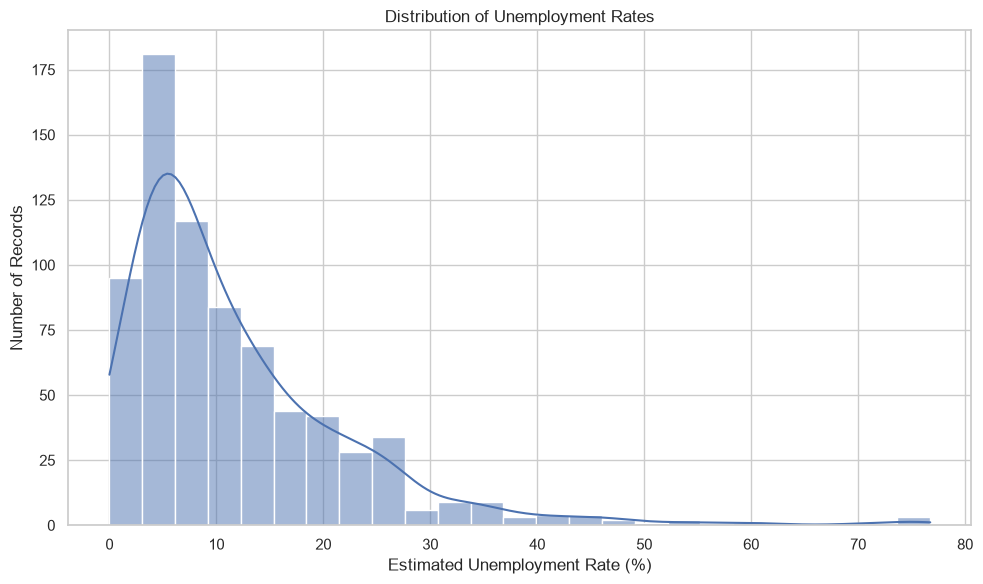

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Estimated Unemployment Rate (%)",
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rates")
plt.xlabel("Estimated Unemployment Rate (%)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()